In [1]:
%load_ext autoreload 
%autoreload 2

## Strength Threshold

Introducing thresholds and plotting their impact on ranks of strongest neighbors.

## 0. Set Up

In [2]:
from itertools import cycle
from pathlib import Path

import matplotlib.pyplot as plt

from network_pluralism.access.utils.labels import (
    get_well_written_section,
)
from network_pluralism.access.utils.df import get_cooccurrence_edge_list_df


In [3]:
def set_rcParams(**kwargs):
    params = {
        "pdf.fonttype": 42,
        "text.usetex": True,
        "font.family": "serif",
        "text.latex.preamble": r"\usepackage{amssymb}\usepackage{amsmath}\usepackage{amsfonts}",
        "font.size": 16,
        "legend.fontsize": 14,
        "legend.title_fontsize": 16,
        "axes.labelsize": 18,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "axes.spines.right": False,
        "axes.spines.top": False,
        "legend.columnspacing": 1.0,
        "legend.frameon": False,
        "lines.linewidth": 3,
    }
    for param in kwargs:
        if param in plt.rcParams.keys():
            params[param] = kwargs[param]
    for k, v in params.items():
        plt.rcParams[k] = v


set_rcParams()

In [4]:
EXPORT_PATH = Path("../../figures_and_results/strength_threshold")
EXPORT_PATH.mkdir(parents=True, exist_ok=True)

## 1. Computation

In [5]:
investigated_unit = "bgb_280"
highlighted_sections = ["bgb_286", "bgb_241", "bgb_634", "bgb_437", "bgb_823"]


In [6]:
section_export_path = EXPORT_PATH / investigated_unit
section_export_path.mkdir(exist_ok=True)

In [7]:
cooccurrence_edge_list_df = get_cooccurrence_edge_list_df(d=3, s=1)

Out Matrix of shape (3111483, 93645)


In [8]:
def get_top_decision_with_min_x_co_on_paragraph_level(cooccurrence_edge_list_df, section, min_coreferences=0):
    top_decision_with_min_x_co_on_paragraph_level = (
        cooccurrence_edge_list_df.query(f's1=="{section}"')
        .groupby(["s2", "r_sem"])
        .count()
        .query(f"s1>{min_coreferences}")
        .sort_values("s1", ascending=False)
        .reset_index()
        .groupby("s2")
        .count()
        .sort_values("r_sem", ascending=False)
    )
    top_decision_with_min_x_co_on_paragraph_level = top_decision_with_min_x_co_on_paragraph_level.drop(
        index=section, errors="ignore"
    )
    return top_decision_with_min_x_co_on_paragraph_level


In [25]:
data_for_viz = {}
i = 0
section = investigated_unit
max_length = 0
max_decisions = {}
while True:
    df = get_top_decision_with_min_x_co_on_paragraph_level(cooccurrence_edge_list_df, section, i)
    if df.empty or df["s1"].max() < 1:
        break
    for rank, n in enumerate(list(df.head(15).index)):
        rank = rank + 1
        if  n  not in data_for_viz:
            data_for_viz[n] = {"Name": [n], "min_ref": [i], "rank": [rank]}
            pass
        else:
            data_for_viz[n]["Name"].append(n)
            data_for_viz[n]["min_ref"].append(i)
            data_for_viz[n]["rank"].append(rank)
    max_length = i
    max_decisions[i] = df["s1"].max()

    i += 1

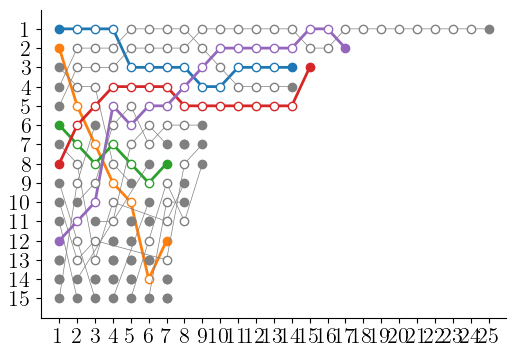

In [26]:
fig, ax = plt.subplots(figsize=(6, 4))

color_cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
colors = cycle(color_cycle)

color_mapping = {}

for element in data_for_viz.values():
    x = [e + 1 for e in element["min_ref"]]
    y = element["rank"]
    color = next(colors) if element["Name"][0] in highlighted_sections else "gray"
    linewidth = 2 if element["Name"][0] in highlighted_sections else 0.5

    if not color == "gray":
        color_mapping[get_well_written_section(element["Name"][0])] = color

    ax.plot(x, y, "-", color=color, linewidth=linewidth)  # just the line

    ax.plot(
        x[1:-1],
        y[1:-1],
        "o",
        markerfacecolor="white",
        markeredgecolor=color,
    )

    # first and last points (solid markers)
    ax.plot(
        [x[0], x[-1]],
        [y[0], y[-1]],
        "o",
        markerfacecolor=color,
        markeredgecolor=color,
    )

# ax.set_ylabel("Rank")
ax.set_ylim(16, 0)
ax.set_yticks(list(range(1, 16)))
ax.set_yticklabels([str(i) for i in range(1, 16)])

# ax.set_ylabel("Rank")
ax.set_xlim(0, max_length + 2)
ax.set_xticks(list(range(1, max_length + 2)))
ax.set_xticklabels([str(i) for i in range(1, max_length + 2)])

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.yaxis.set_ticks_position("left")
ax.xaxis.set_ticks_position("bottom")
ax.tick_params(top=False, right=False)

# ax.set_xlabel("Minimum references per decision")
plt.savefig(section_export_path / "ranks.pdf", dpi=600, transparent=True)